<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# An unknown reputation is not a negative verdict

Triage a small event stream offline, retrieve normalized reputation only for eligible distinct indicators, and preserve the difference between no lookup, no verdict, an explicit negative verdict and a positive verdict without a score. Then vary a score threshold for a review queue.

**Synthetic local fixture only.** Every reputation verdict, score and category is invented. Reserved `.example` names, documentation/private addresses and a repeated-character hash illustrate the workflow. No listed indicator is contacted, and no live threat-intelligence provider or credential is used. The real released worker calls a disposable loopback HTTP endpoint using its supported `base_url` option.

## Choose a review-queue score threshold

`MIN_SCORE` accepts an integer from **0 to 100**, default **70**. The focused experiment uses **90**. A candidate must have both a positive provider verdict and a nonnull score at or above this inclusive threshold. This invented feed uses a 0–100 ordering; it is **not a probability** and has no calibration to any real vendor. Restart and run all after editing.

In [1]:
MIN_SCORE = 70

In [2]:
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from local_feed import LocalFeed
from notebook_support import finish, theme

assert isinstance(MIN_SCORE, int) and not isinstance(MIN_SCORE, bool) and 0 <= MIN_SCORE <= 100
theme()
feed = LocalFeed()
FIXTURE_URL = feed.url
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-threatintel/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-threatintel/notebooks/pyproject.toml.

## Classify and deduplicate before requesting reputation

The literal `github-auto` location starts the pinned public native release. SQL calls the worker’s offline classifiers on the full event column. Private/reserved IP literals are excluded from lookup; a non-IP returns false for `is_private_ip`, so a separate recognized-type check is essential. Classification is lexical: it does not resolve a domain, inspect a URL host’s network address, defang text or validate file contents.

`phish.example` occurs in two events. Deduplicating requests avoids treating repeat observations as independent intelligence, while a later join restores event-level provenance. Null and malformed inputs remain distinguishable.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'threatintel' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-threatintel@v0.4.0');
CREATE TABLE events AS SELECT * FROM (VALUES
 (1,'phish.example'),(2,'phish.example'),(3,'loader.example'),(4,'unscored.example'),
 (5,'clean.example'),(6,'unknown.example'),(7,'https://download.example/payload'),
 (8,repeat('a',64)),(9,'10.0.0.5'),(10,'198.51.100.7'),(11,'not-an-indicator!!'),(12,NULL)
) AS t(event_id,indicator);
CREATE TABLE typed AS SELECT *,threatintel.main.indicator_type(indicator) AS kind,
 threatintel.main.is_private_ip(indicator) AS private_or_reserved FROM events;
CREATE TABLE eligible AS SELECT DISTINCT indicator,kind FROM typed
 WHERE kind IS NOT NULL AND NOT private_or_reserved;

,Count


In [4]:
%%sql triage <<
SELECT t.*,CASE WHEN indicator IS NULL THEN 'missing input'
 WHEN kind IS NULL THEN 'unrecognized'
 WHEN private_or_reserved THEN 'private/reserved IP' ELSE 'lookup eligible' END AS route
FROM typed t ORDER BY event_id;

In [5]:
display(triage)

,event_id,indicator,kind,private_or_reserved,route
0,1,phish.example,domain,False,lookup eligible
1,2,phish.example,domain,False,lookup eligible
2,3,loader.example,domain,False,lookup eligible
3,4,unscored.example,domain,False,lookup eligible
4,5,clean.example,domain,False,lookup eligible
5,6,unknown.example,domain,False,lookup eligible
6,7,https://download.example/payload,url,False,lookup eligible
7,8,aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa...,sha256,False,lookup eligible
8,9,10.0.0.5,ipv4,True,private/reserved IP
9,10,198.51.100.7,ipv4,True,private/reserved IP


## Retrieve supported literal arguments once

This release’s `reputation` table function accepts literal arguments, not a LATERAL symbol column. The seven explicit calls below correspond to the displayed distinct eligible inputs. They use the local normalized endpoint, not the worker’s placeholder default provider. Each response is materialized by this CTAS before any captured display.

The fixture returns HTTP 404 for `unknown.example`, which the worker represents as **zero rows**. A negative verdict returns a row with `malicious = false`; a positive verdict may have a null score. Authentication, rate-limit and server errors are errors, not unknown verdicts.

In [6]:
%%sql
CREATE TABLE verdicts AS
SELECT * FROM threatintel.main.reputation('phish.example',
 base_url:='{{ FIXTURE_URL }}',timeout_ms:=3000)
UNION ALL
SELECT * FROM threatintel.main.reputation('loader.example',
 base_url:='{{ FIXTURE_URL }}',timeout_ms:=3000)
UNION ALL
SELECT * FROM threatintel.main.reputation('unscored.example',
 base_url:='{{ FIXTURE_URL }}',timeout_ms:=3000)
UNION ALL
SELECT * FROM threatintel.main.reputation('clean.example',
 base_url:='{{ FIXTURE_URL }}',timeout_ms:=3000)
UNION ALL
SELECT * FROM threatintel.main.reputation('unknown.example',
 base_url:='{{ FIXTURE_URL }}',timeout_ms:=3000)
UNION ALL
SELECT * FROM threatintel.main.reputation('https://download.example/payload',
 base_url:='{{ FIXTURE_URL }}',timeout_ms:=3000)
UNION ALL
SELECT * FROM threatintel.main.reputation('aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa',
 base_url:='{{ FIXTURE_URL }}',timeout_ms:=3000);

,Count


In [7]:
%%sql reputation <<
SELECT indicator,type,malicious,score,categories,source,last_seen FROM verdicts ORDER BY indicator;

In [8]:
display(reputation)

,indicator,type,malicious,score,categories,source,last_seen
0,aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa...,sha256,True,96.0,[synthetic-hash],invented-normalized-feed,2026-01-15T12:00:00Z
1,clean.example,domain,False,5.0,[],invented-normalized-feed,2026-01-15T12:00:00Z
2,https://download.example/payload,url,True,88.0,[payload],invented-normalized-feed,2026-01-15T12:00:00Z
3,loader.example,domain,True,78.0,[loader],invented-normalized-feed,2026-01-15T12:00:00Z
4,phish.example,domain,True,92.0,[phishing],invented-normalized-feed,2026-01-15T12:00:00Z
5,unscored.example,domain,True,NaN,[unscored],invented-normalized-feed,2026-01-15T12:00:00Z


## Join verdicts back without filling unknowns with zero

A left join retains all original event IDs. The queue status first records why a lookup did not happen, then distinguishes no returned verdict, a negative verdict, an unscored positive verdict, and scored positive verdicts on either side of the threshold. Provider `malicious` and the local queue decision stay separate columns. A threshold cannot make an unknown indicator safe or assign a score to a missing measurement.

In [9]:
%%sql
CREATE TABLE assessed AS SELECT t.*,v.indicator AS returned_indicator,v.type AS feed_type,
 v.malicious,v.score,v.categories,v.source,v.last_seen,
 CASE WHEN t.indicator IS NULL THEN 'missing input'
 WHEN t.kind IS NULL THEN 'unrecognized'
 WHEN t.private_or_reserved THEN 'private/reserved IP'
 WHEN v.indicator IS NULL THEN 'no verdict'
 WHEN NOT v.malicious THEN 'negative verdict'
 WHEN v.score IS NULL THEN 'positive, unscored'
 WHEN v.score >= {{ MIN_SCORE }} THEN 'review candidate'
 ELSE 'positive, below threshold' END AS queue_status
FROM typed t LEFT JOIN verdicts v USING(indicator);
CREATE TABLE coverage AS SELECT queue_status,count(*) AS event_rows,
 count(DISTINCT indicator) AS distinct_indicators FROM assessed GROUP BY queue_status;

,Count


In [10]:
%%sql counts <<
SELECT * FROM coverage ORDER BY event_rows DESC,queue_status;

In [11]:
%%sql scored <<
SELECT DISTINCT indicator,kind,malicious,score,queue_status FROM assessed WHERE score IS NOT NULL ORDER BY score;

,queue_status,event_rows,distinct_indicators
0,review candidate,5,4
1,private/reserved IP,2,2
2,missing input,1,0
3,negative verdict,1,1
4,no verdict,1,1
5,"positive, unscored",1,1
6,unrecognized,1,1


,indicator,kind,malicious,score,queue_status
0,clean.example,domain,False,5.0,negative verdict
1,loader.example,domain,True,78.0,review candidate
2,https://download.example/payload,url,True,88.0,review candidate
3,phish.example,domain,True,92.0,review candidate
4,aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa...,sha256,True,96.0,review candidate


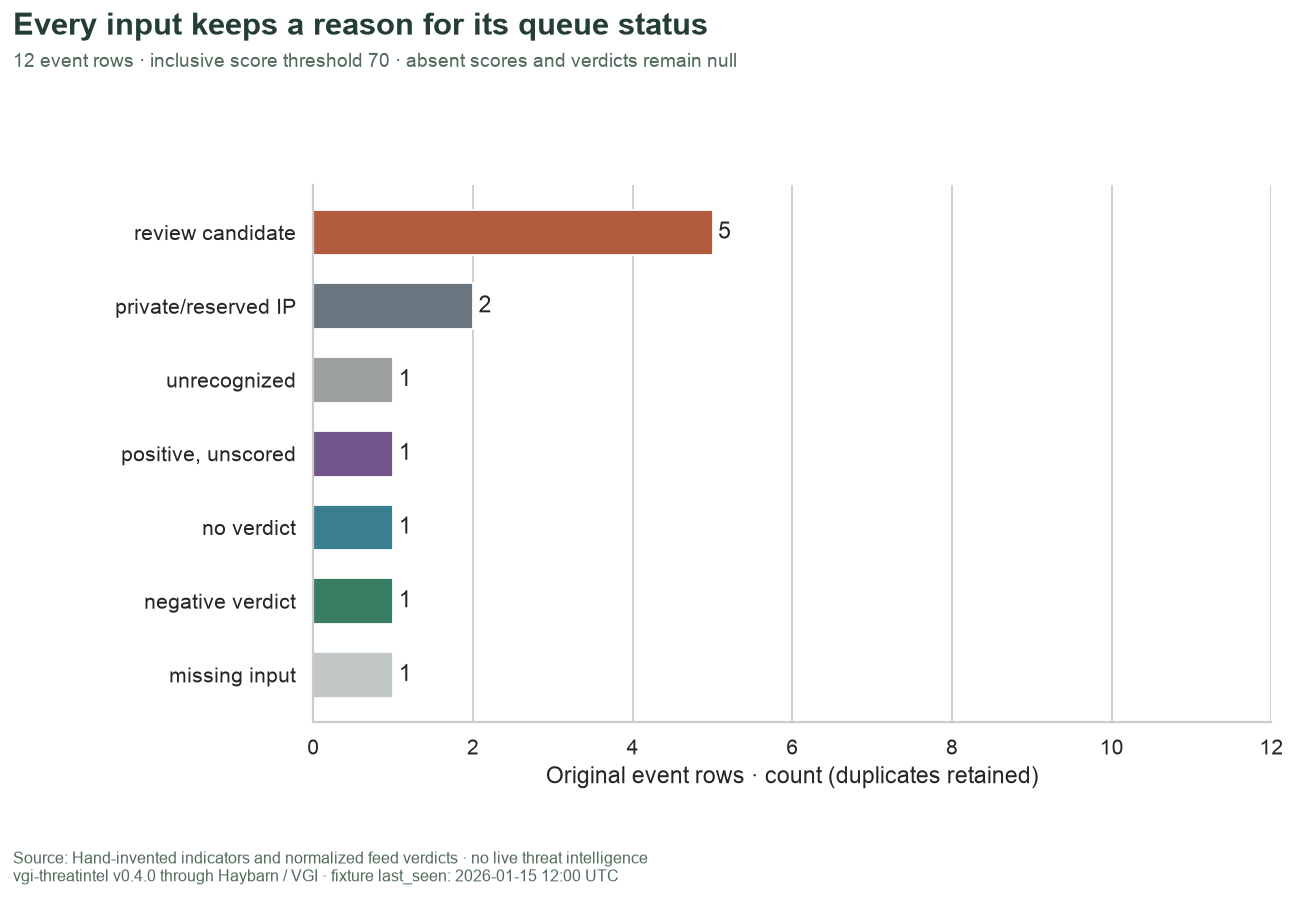

In [12]:
display(counts)
display(scored)
order = counts.sort_values(["event_rows", "queue_status"])
colors = {
    "review candidate": "#b25b3f",
    "positive, below threshold": "#b48c49",
    "positive, unscored": "#71568b",
    "negative verdict": "#397d62",
    "no verdict": "#397f91",
    "private/reserved IP": "#69757f",
    "unrecognized": "#9b9f9e",
    "missing input": "#c1c8c4",
}
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(order.queue_status, order.event_rows, color=[colors[s] for s in order.queue_status], height=0.62)
for i, row in enumerate(order.itertuples()):
    ax.text(row.event_rows + 0.07, i, str(int(row.event_rows)), va="center")
ax.set(xlabel="Original event rows · count (duplicates retained)", ylabel="", xlim=(0, len(triage)))
ax.set_xticks(range(0, len(triage) + 1, 2))
ax.grid(axis="y", visible=False)
finish(
    fig,
    f"coverage-{MIN_SCORE}",
    "Every input keeps a reason for its queue status",
    f"{len(triage)} event rows · inclusive score threshold {MIN_SCORE} · absent scores and verdicts remain null",
)

## Inspect the scored subset without hiding its exclusions

This panel shows distinct indicators with an actual numeric score. The positive-but-unscored verdict remains in the coverage table and has no bar. A negative verdict is labeled explicitly even if a lower threshold would admit its numeric score. The repeated-character SHA-256 is abbreviated only on the chart; the complete value remains in SQL output. No bytes are downloaded or scanned.

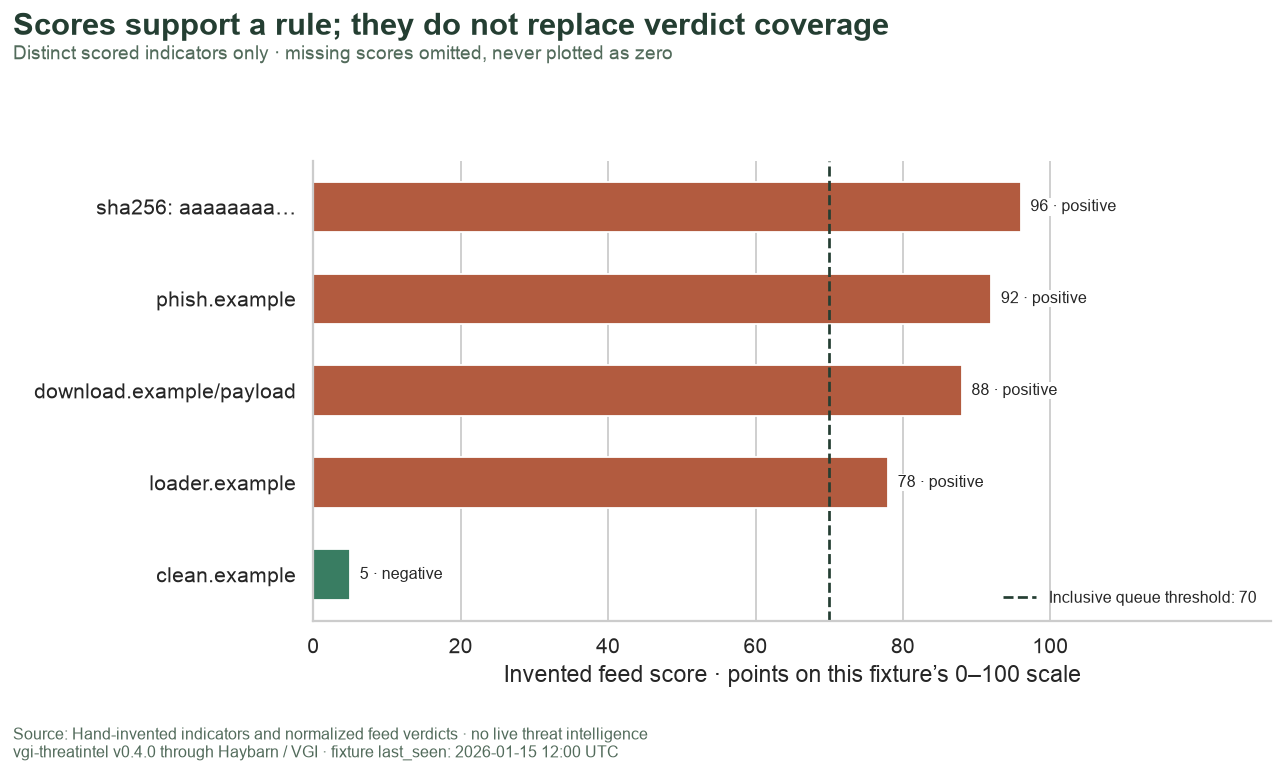

In [13]:
fig, ax = plt.subplots(figsize=(11, 6))
labels = ["sha256: " + s[:8] + "…" if len(s) == 64 else s.replace("https://", "") for s in scored.indicator]
ax.barh(labels, scored.score, color=[colors[s] for s in scored.queue_status], height=0.55)
for i, row in enumerate(scored.itertuples()):
    ax.text(
        row.score + 1.3, i, f"{row.score:g} · {'positive' if row.malicious else 'negative'}", va="center", fontsize=9
    )
for label in ax.texts:
    label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 0.5})
    label.set_zorder(5)
ax.axvline(MIN_SCORE, color="#243e32", linestyle="--", label=f"Inclusive queue threshold: {MIN_SCORE}")
ax.set(xlabel="Invented feed score · points on this fixture’s 0–100 scale", ylabel="", xlim=(0, 130))
ax.set_xticks(range(0, 101, 20))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
finish(
    fig,
    f"scores-{MIN_SCORE}",
    "Scores support a rule; they do not replace verdict coverage",
    "Distinct scored indicators only · missing scores omitted, never plotted as zero",
)

In [14]:
candidates = int(counts.loc[counts.queue_status == "review candidate", "event_rows"].sum())
unique_candidates = int(counts.loc[counts.queue_status == "review candidate", "distinct_indicators"].sum())
unknown = int(counts.loc[counts.queue_status == "no verdict", "event_rows"].sum())
unscored = int(counts.loc[counts.queue_status == "positive, unscored", "event_rows"].sum())
display(
    Markdown(
        f"At threshold **{MIN_SCORE}**, the queue contains **{candidates} event rows** for "
        f"**{unique_candidates} distinct indicators**. The no-verdict count is **{unknown}** "
        f"and the positive-but-unscored count is **{unscored}**. "
        "Repeated events affect queue volume, not the number of feed verdicts. "
        "A smaller queue after raising the threshold would reflect the rule change, "
        "not fewer threats or improved intelligence."
    )
)

At threshold **70**, the queue contains **5 event rows** for **4 distinct indicators**. The no-verdict count is **1** and the positive-but-unscored count is **1**. Repeated events affect queue volume, not the number of feed verdicts. A smaller queue after raising the threshold would reflect the rule change, not fewer threats or improved intelligence.

## Verify coverage and the local request boundary

These checks cover event identity, distinct retrieval, row mapping, eligibility, null preservation and threshold semantics. The request journal must contain exactly the eligible indicator set and only HTTP 200/404 responses. It does not infer a trustworthy source from a syntactically valid indicator or assert that a fixture verdict is true in the world.

In [15]:
%%sql checks <<
SELECT 'original event identities remain complete' AS check_name,
 (SELECT count(*)=count(DISTINCT event_id) AND count(*)=(SELECT count(*) FROM events) FROM assessed) AS passed
UNION ALL SELECT 'verdict indicators are unique',(SELECT count(*)=count(DISTINCT indicator) FROM verdicts)
UNION ALL SELECT 'every returned verdict was eligible',
 (SELECT count(*)=0 FROM verdicts v ANTI JOIN eligible e USING(indicator))
UNION ALL SELECT 'feed and offline types agree',(SELECT bool_and(feed_type=kind) FROM assessed WHERE returned_indicator IS NOT NULL)
UNION ALL SELECT 'nonlooked-up events have no verdict',
 (SELECT bool_and(returned_indicator IS NULL) FROM assessed WHERE kind IS NULL OR private_or_reserved)
UNION ALL SELECT 'unknown verdicts preserve null score and flag',
 (SELECT bool_and(score IS NULL AND malicious IS NULL) FROM assessed WHERE queue_status='no verdict')
UNION ALL SELECT 'negative verdict remains explicit',
 (SELECT bool_and(malicious=false) FROM assessed WHERE queue_status='negative verdict')
UNION ALL SELECT 'unscored positive verdict remains null',
 (SELECT bool_and(malicious=true AND score IS NULL) FROM assessed WHERE queue_status='positive, unscored')
UNION ALL SELECT 'queue candidates meet both conditions',
 coalesce((SELECT bool_and(malicious AND score>={{ MIN_SCORE }}) FROM assessed WHERE queue_status='review candidate'),true)
UNION ALL SELECT 'scored positives below threshold are excluded',
 coalesce((SELECT bool_and(malicious AND score<{{ MIN_SCORE }}) FROM assessed WHERE queue_status='positive, below threshold'),true)
UNION ALL SELECT 'fixture score scale is respected',(SELECT bool_and(score BETWEEN 0 AND 100) FROM verdicts WHERE score IS NOT NULL)
UNION ALL SELECT 'queue statuses partition all events',(SELECT sum(event_rows)=(SELECT count(*) FROM events) FROM coverage);

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
expected = set(triage.loc[triage.route == "lookup eligible", "indicator"])
assert {r["indicator"] for r in feed.requests} == expected
assert all(r["status"] in (200, 404) for r in feed.requests)
assert any(r["status"] == 404 for r in feed.requests)
display(
    Markdown(
        f"**{len(checks)} SQL checks passed**, plus request-set and HTTP-status checks. "
        f"The local fixture received **{len(feed.requests)} GET requests** "
        f"for **{len(expected)} distinct eligible indicators**."
    )
)
display(feed.requests)
Path("validation/requests.json").write_text(json.dumps(feed.requests, indent=2) + "\n")

,check_name,passed
0,original event identities remain complete,True
1,verdict indicators are unique,True
2,every returned verdict was eligible,True
3,feed and offline types agree,True
4,nonlooked-up events have no verdict,True
5,unknown verdicts preserve null score and flag,True
6,negative verdict remains explicit,True
7,unscored positive verdict remains null,True
8,queue candidates meet both conditions,True
9,scored positives below threshold are excluded,True


**12 SQL checks passed**, plus request-set and HTTP-status checks. The local fixture received **7 GET requests** for **7 distinct eligible indicators**.

[{'indicator': 'phish.example', 'status': 200},
 {'indicator': 'loader.example', 'status': 200},
 {'indicator': 'unscored.example', 'status': 200},
 {'indicator': 'clean.example', 'status': 200},
 {'indicator': 'unknown.example', 'status': 404},
 {'indicator': 'https://download.example/payload', 'status': 200},
 {'indicator': 'aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa',
  'status': 200}]

506

## Focused experiment: raise the review threshold

Change only **`MIN_SCORE` from 70 to 90**, restart and run all. Predict that positive, scored indicators in **[70,90)** leave the review-candidate category. Compare both event volume and distinct-indicator count; their changes may differ because the same indicator can occur repeatedly.

The raw provider verdict table, numeric scores, unknown count and unscored-positive count should remain identical. This changes queue policy, not ground truth, risk, source quality or detection recall. Restore **70** for the baseline; the README saves the experiment separately.

In [17]:
connection.close()
feed.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>